# NC3 Figure Reproducibility Instructions

**Project:** Lansing Economic Ecosystem and Community Wealth Analysis
**Team:** NC3, with the Lansing Growth Fund
**File:** `figure_instructions/reproduce_figures.ipynb`

This notebook is the instruction file for every figure currently used in the project.
Restart the kernel and run all cells. Each cell loads committed data, writes an
intermediate table, draws one figure, and exports a PNG.

## Where these figures are used

| Export | What it shows | Where that figure is used |
| --- | --- | --- |
| `figures/01_laus_unemployment_rate.png` | Monthly MSA unemployment rate | `notebooks/baseline_visualizations.ipynb` section 1. This is chart 1 of the install demo in `INSTALL.md`. |
| `figures/02_qcew_msa_ownership.png` | 2024 MSA employment by ownership | `notebooks/baseline_visualizations.ipynb` section 2. Install demo chart 2. |
| `figures/03_industry_standins.png` | Employment in Big 4 industry stand-ins | `notebooks/baseline_visualizations.ipynb` section 3. Install demo chart 3. |
| `figures/04_median_income_by_geography.png` | Median household income by geography | `notebooks/baseline_visualizations.ipynb` section 4. Install demo chart 4. |
| `figures/05_laus_annual_average.png` | Annual mean unemployment rate | `notebooks/NC3_Partner_Meeting_Snapshot.ipynb` labor-market section. Partner meeting, November 2026. |
| `figures/06_tricounty_ownership.png` | 2024 tri-county employment by ownership | Same partner snapshot, employment section. |
| `figures/07_county_median_income.png` | Median household income for the three counties | Partner snapshot and `notebooks/NC3_Lansing_Findings_Correlation.ipynb`. |
| `figures/08_gm_regional_employment.png` | GM regional employment, 2016 and 2025 | `notebooks/NC3_GM_Data_Correlation.ipynb` section 1. |
| `figures/09_gm_combined_taxable_value.png` | Combined GM taxable value in the City of Lansing | GM notebook section 2 and the findings notebook. |
| `figures/10_delta_assembly_taxable_value.png` | Delta Township Assembly taxable value | GM notebook section 3 and findings notebook section 6. |
| `figures/11_city_county_msa_income.png` | City, county, and MSA median income | Findings notebook section 3. |
| `figures/12_county_correlation.png` | Cross-county correlation heatmap | Findings notebook section 4. |
| `figures/13_state_gov_share_vs_income.png` | State-government job share vs. income | Findings notebook section 5. |
| `figures/14_naics336_share_vs_poverty.png` | Transportation-equipment job share vs. poverty | Findings notebook section 5. |
| `figures/15_top_tracts_by_poverty.png` | Ten highest-poverty tracts | `notebooks/NC3_Tract_Mismatch_Snapshot.ipynb`. |
| `figures/16_lowest_income_tracts.png` | Ten lowest-income tracts | Same tract notebook. |
| `figures/17_big4_employment_range.png` | Big 4 employment low-to-high range, 2025 | `Individual_TeamMember_files/wangz153/01_footprint.ipynb`. Scorecard draft for the report. |
| `figures/18_employment_index_2019.png` | Employment indexed to 2019 | Same footprint notebook, section 4. |
| `figures/19_local_resident_capture.png` | Share of workers who live in the three counties | `Individual_TeamMember_files/wangz153/02_retention.ipynb`. |
| `figures/20_poverty_near_sites.png` | Poverty rate near each Big 4 site | `Individual_TeamMember_files/wangz153/03_benefit.ipynb`. |
| `figures/21_jobs_vs_poverty.png` | Tract jobs vs. resident poverty | Same benefit notebook. |
| `figures/22_lansing_census_api.png` | Optional live Census API chart | `notebooks/baseline_visualizations.ipynb` section 5. Off unless you turn it on. |

The partner notebooks display charts with Plotly and do not save image files.
This notebook redraws those charts with matplotlib and saves PNG files.
Static export does not need the `kaleido` package, which is not in `environment.yml`.

## Install first

Follow `INSTALL.md` at the repository root before you run this notebook.

You need:

1. Git, Miniconda or Anaconda, and access to this repository.
2. The `nc3` environment from `environment.yml` (`conda env create --file environment.yml`, then `conda activate nc3`).
3. The committed files in `Data_Files/`. They are already in the repository. `Data_Files/README.md` explains each file and how to refresh it later.

Confirm the install with the test in `INSTALL.md` section 6 if you have not already.
That test runs `notebooks/baseline_visualizations.ipynb`. This file then exports the same four demo charts plus the rest of the project figures.

## How to run

From the repository root, with the `nc3` environment active:

```bash
jupyter lab
```

Open `figure_instructions/reproduce_figures.ipynb`. Select the **Python (NC3)** kernel if it is not already selected. Then use **Kernel → Restart Kernel and Run All Cells**.

You can also run it from this folder. The setup cell walks upward until it finds `Data_Files/` and `INSTALL.md`, so the working directory can be the repository root or `figure_instructions/`.

A full run of this notebook should finish in about a minute. It only reads files that are already in the repository.

## Slow steps and intermediate files

Two kinds of intermediate files are used.

**Written here, and safe to delete.** Each section saves the table that the figure actually plots to `figure_instructions/intermediate/`. If you want to inspect a figure without re-reading the raw extracts, open that CSV. Re-running the notebook overwrites these files.

**Already stored, because they take longer to rebuild.** The five scorecard charts (figures 17–21) read tables committed at:

```text
Individual_TeamMember_files/wangz153/outputs/
```

Those tables are the output of `01_footprint.ipynb`, `02_retention.ipynb`, and `03_benefit.ipynb`. Building them reads the local QCEW, ACS, ACFR, and LODES extracts. Notebook 02 reads `Data_Files/lodes_od_tri_workplace_2021_agg.csv.gz`, which is committed, so you do not need to download LODES again. Expect several minutes if you choose to rebuild them.

To rebuild the scorecard tables instead of using the stored copies:

1. Activate `nc3` and start JupyterLab from the repository root.
2. Open and run all cells in `01_footprint.ipynb`, then `02_retention.ipynb`, then `03_benefit.ipynb`.
3. Come back to this notebook and run all cells. Figures 17–21 will use the new CSVs.

Skip that rebuild for a normal review. The stored CSVs are the inputs this notebook expects.

## Manual steps

- Leave `RUN_LIVE_CENSUS = False` in the setup cell. Figure 22 is the optional Census API example from the baseline notebook. It needs internet and no API key. Set the flag to `True` and re-run the last code cell if you want that PNG.
- Do not commit API keys, the ACFR PDF, or full LODES state files. This notebook does not request them.
- No NDA data is used. Every input path below is a public extract already in the repository.

## What a successful run prints

The last cell prints 21 exported PNG paths (22 if the Census flag is on) and writes `intermediate/figure_index.csv`.


In [1]:
# Setup. Run this cell first. Later cells expect these names to exist.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

# The live Census chart is optional and needs internet. Leave this False
# for a normal review. Instructions for turning it on are in the last section.
RUN_LIVE_CENSUS = False

HERE = Path.cwd().resolve()
REPO_ROOT = None
for folder in [HERE, *HERE.parents]:
    if (folder / "Data_Files").is_dir() and (folder / "INSTALL.md").is_file():
        REPO_ROOT = folder
        break
if REPO_ROOT is None:
    raise FileNotFoundError(
        "Could not find the NC3 repository root (a folder that contains "
        "Data_Files/ and INSTALL.md). Clone the repository and follow INSTALL.md, "
        "then open this notebook from that checkout."
    )

DATA_DIR = REPO_ROOT / "Data_Files"
FIG_DIR = REPO_ROOT / "figure_instructions" / "figures"
INTERMEDIATE_DIR = REPO_ROOT / "figure_instructions" / "intermediate"
SCORECARD_DIR = REPO_ROOT / "Individual_TeamMember_files" / "wangz153" / "outputs"
FIG_DIR.mkdir(parents=True, exist_ok=True)
INTERMEDIATE_DIR.mkdir(parents=True, exist_ok=True)

REQUIRED = [
    DATA_DIR / "laus_lansing_msa_2019_latest.csv",
    DATA_DIR / "qcew_2024_a_focus.csv",
    DATA_DIR / "acs_2024_key_indicators.csv",
    DATA_DIR / "acs_tract_2020_2024.csv",
    DATA_DIR / "lansing_acfr_fy2025_principal_employers.csv",
    DATA_DIR / "lansing_acfr_fy2025_principal_taxpayers.csv",
    DATA_DIR / "lansing_gm_area_parcels_values.csv",
    SCORECARD_DIR / "footprint_v0_2025.csv",
    SCORECARD_DIR / "footprint_timeseries_2019_2025.csv",
    SCORECARD_DIR / "retention_v0_wages.csv",
    SCORECARD_DIR / "benefit_v0_site_neighborhoods.csv",
    SCORECARD_DIR / "benefit_v0_tracts.csv",
]
missing = [str(path.relative_to(REPO_ROOT)) for path in REQUIRED if not path.exists()]
if missing:
    raise FileNotFoundError(
        "Missing files:\n  " + "\n  ".join(missing) +
        "\n\nPublic extracts belong in Data_Files/. See Data_Files/README.md and INSTALL.md."
        "\nScorecard tables belong in Individual_TeamMember_files/wangz153/outputs/."
        "\nIf those outputs are missing, run 01_footprint.ipynb, 02_retention.ipynb, "
        "and 03_benefit.ipynb, then re-run this notebook."
    )

# Colors follow the institution in every scorecard chart. Same palette as nc3_helpers.py.
BIG4_COLORS = {
    "MSU": "#2a78d6",
    "GM": "#eb6834",
    "State Government": "#1baf7a",
    "Local Government": "#eda100",
}
REGION_COLOR = "#8a8984"
SITES = {
    "MSU campus": (42.7164, -84.4850, "MSU"),
    "State Capitol complex": (42.7337, -84.5555, "State Government"),
    "GM Lansing Grand River": (42.7238, -84.5614, "GM"),
    "GM Lansing Delta Township": (42.6908, -84.6881, "GM"),
}

EXPORTED = []


def save_table(df, stem, index=False):
    """Write the table a figure plots so a reviewer can open it without re-running the munging."""
    path = INTERMEDIATE_DIR / f"{stem}.csv"
    df.to_csv(path, index=index)
    print(f"Intermediate  intermediate/{path.name}  ({len(df)} rows)")
    return path


def export(fig, stem, description, used_in):
    """Save a PNG, keep a row for the index, and show the figure in the notebook."""
    path = FIG_DIR / f"{stem}.png"
    fig.savefig(path, dpi=160, bbox_inches="tight", facecolor="white")
    display(fig)
    plt.close(fig)
    EXPORTED.append({
        "file": f"figures/{path.name}",
        "description": description,
        "used_in": used_in,
    })
    print(f"Exported      figures/{path.name}")
    return path


def source_note(fig, text):
    fig.text(0.0, -0.02, text, fontsize=8, color="#52514e")


print("Repository root:", REPO_ROOT)
print("Required inputs found.")
print("RUN_LIVE_CENSUS =", RUN_LIVE_CENSUS)


Repository root: C:\Users\swens\PycharmProjects\CMSE 495\NC3
Required inputs found.
RUN_LIVE_CENSUS = False


## 1. Baseline demo figures

These four charts are the install demo in `INSTALL.md` section 6 and the body of `notebooks/baseline_visualizations.ipynb`.

Inputs, all committed:

- `Data_Files/laus_lansing_msa_2019_latest.csv` — BLS LAUS, Lansing–East Lansing MSA, not seasonally adjusted
- `Data_Files/qcew_2024_a_focus.csv` — BLS QCEW annual averages for 2024
- `Data_Files/acs_2024_key_indicators.csv` — ACS 2024 5-year estimates

Ownership codes used on the QCEW charts: 1 federal, 2 state government (this includes public universities, so do not add MSU on top of it), 3 local government, 5 private. Industry `10` is the all-industry total. Suppressed QCEW cells are disclosure code `N` and are stored as 0. This notebook sets those employment values to missing before any total or chart.

The next cell builds the three analysis tables. The four cells after it only format and export.


In [2]:
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

laus = pd.read_csv(DATA_DIR / "laus_lansing_msa_2019_latest.csv")
ur = laus[laus["measure"] == "unemployment_rate"].copy()
ur["value"] = pd.to_numeric(ur["value"], errors="coerce")
ur["date"] = pd.to_datetime(
    ur["year"].astype(str) + "-" + ur["period"].str[1:],
    format="%Y-%m",
)
ur = ur.dropna(subset=["value"]).sort_values("date")
save_table(ur[["date", "year", "period", "value"]], "01_laus_unemployment_rate")

qcew = pd.read_csv(
    DATA_DIR / "qcew_2024_a_focus.csv",
    dtype={"industry_code": str, "area_fips": str},
)
qcew["own_code"] = pd.to_numeric(qcew["own_code"], errors="coerce")
qcew["annual_avg_emplvl"] = pd.to_numeric(qcew["annual_avg_emplvl"], errors="coerce")
qcew["avg_annual_pay"] = pd.to_numeric(qcew["avg_annual_pay"], errors="coerce")
suppressed = qcew["disclosure_code"].astype(str).str.upper().eq("N")
qcew.loc[suppressed, ["annual_avg_emplvl", "avg_annual_pay"]] = np.nan

msa_own = qcew[
    (qcew["area_name"] == "Lansing_MSA")
    & (qcew["industry_code"] == "10")
    & (qcew["own_code"].isin([1, 2, 3, 5]))
].copy()
ownership_labels = {
    1: "Federal",
    2: "State Gov (incl. MSU)",
    3: "Local Gov",
    5: "Private",
}
msa_own["ownership"] = msa_own["own_code"].map(ownership_labels)
save_table(
    msa_own[["ownership", "own_code", "annual_avg_emplvl", "avg_annual_pay"]],
    "02_qcew_msa_ownership",
)

standins = qcew[
    (qcew["area_name"] == "Lansing_MSA")
    & (qcew["industry_code"].isin(["10", "336", "611", "92"]))
    & (qcew["own_code"].isin([0, 2, 5]))
].copy()
standins["label"] = standins["industry_code"] + " (own " + standins["own_code"].astype(int).astype(str) + ")"
save_table(
    standins[["label", "industry_code", "own_code", "annual_avg_emplvl"]],
    "03_industry_standins",
)

acs = pd.read_csv(DATA_DIR / "acs_2024_key_indicators.csv")
mhi = acs[acs["table_id"] == "B19013"][["geo_name", "estimate"]].drop_duplicates()
mhi = mhi.sort_values("estimate", ascending=False)
save_table(mhi, "04_median_income_by_geography")
print("Baseline tables are ready.")


Intermediate  intermediate/01_laus_unemployment_rate.csv  (91 rows)
Intermediate  intermediate/02_qcew_msa_ownership.csv  (4 rows)
Intermediate  intermediate/03_industry_standins.csv  (5 rows)
Intermediate  intermediate/04_median_income_by_geography.csv  (6 rows)
Baseline tables are ready.


### Figure 1. Monthly unemployment rate

**Used in:** `notebooks/baseline_visualizations.ipynb` section 1, and as the first chart of the `INSTALL.md` demo.

The series is the not-seasonally-adjusted unemployment rate (`measure == unemployment_rate`). `period` values such as `M01` are turned into a month, then combined with `year`. The dashed line is the mean of the plotted points.


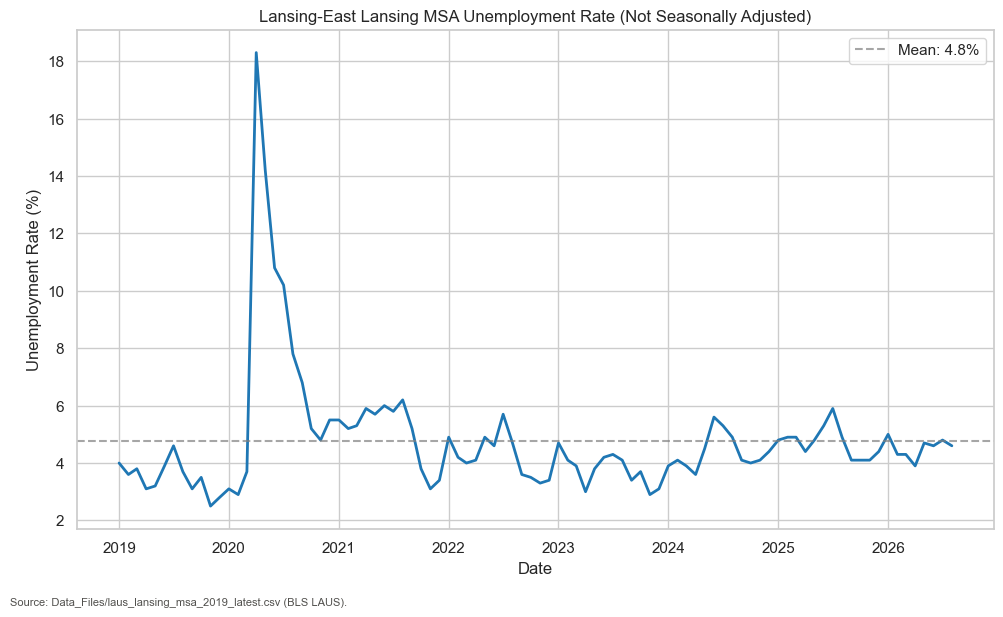

Exported      figures/01_laus_unemployment_rate.png
Latest rate: 4.6% (Aug 2026)


In [3]:
fig, ax = plt.subplots()
ax.plot(ur["date"], ur["value"], linewidth=2, color="#1f77b4")
mean_rate = ur["value"].mean()
ax.axhline(mean_rate, color="gray", linestyle="--", alpha=0.7, label=f"Mean: {mean_rate:.1f}%")
ax.set_title("Lansing-East Lansing MSA Unemployment Rate (Not Seasonally Adjusted)")
ax.set_xlabel("Date")
ax.set_ylabel("Unemployment Rate (%)")
ax.legend()
fig.tight_layout()
source_note(fig, "Source: Data_Files/laus_lansing_msa_2019_latest.csv (BLS LAUS).")
export(
    fig,
    "01_laus_unemployment_rate",
    "Monthly not-seasonally-adjusted unemployment rate, Lansing-East Lansing MSA.",
    "notebooks/baseline_visualizations.ipynb section 1; INSTALL.md demo chart 1.",
)
latest = ur.iloc[-1]
print(f"Latest rate: {latest['value']:.1f}% ({latest['date'].strftime('%b %Y')})")


### Figure 2. MSA employment by ownership

**Used in:** `notebooks/baseline_visualizations.ipynb` section 2, and as the second chart of the `INSTALL.md` demo.

Rows are Lansing MSA (`area_name == Lansing_MSA`), all industries (`industry_code == 10`), ownership codes 1, 2, 3, and 5. The bar labels are the average employment counts from QCEW.


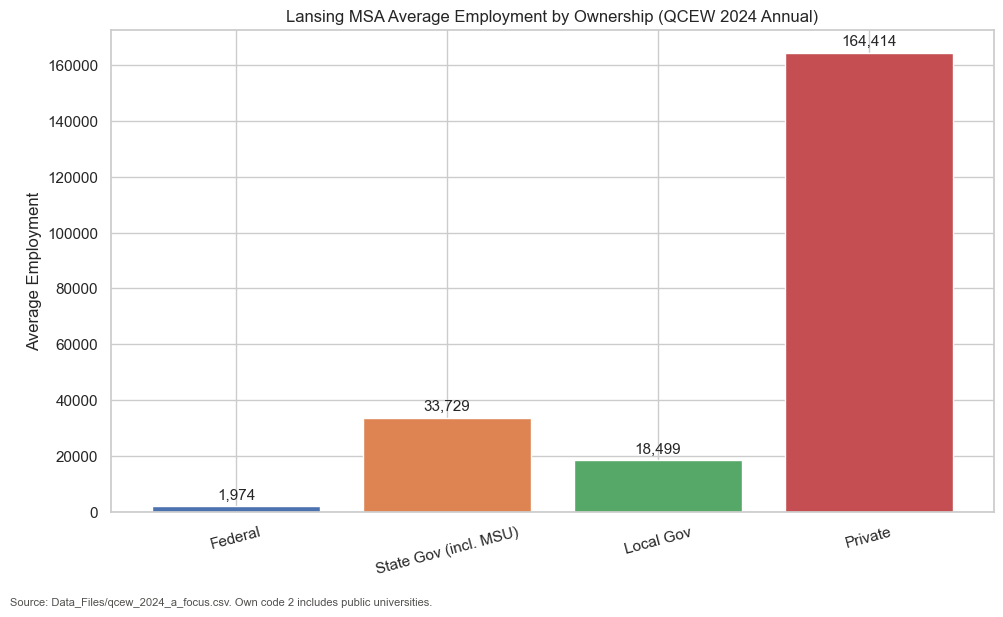

Exported      figures/02_qcew_msa_ownership.png


WindowsPath('C:/Users/swens/PycharmProjects/CMSE 495/NC3/figure_instructions/figures/02_qcew_msa_ownership.png')

In [4]:
fig, ax = plt.subplots()
colors = sns.color_palette("deep", len(msa_own))
bars = ax.bar(msa_own["ownership"], msa_own["annual_avg_emplvl"], color=colors)
ax.set_title("Lansing MSA Average Employment by Ownership (QCEW 2024 Annual)")
ax.set_ylabel("Average Employment")
ax.tick_params(axis="x", rotation=15)
ax.bar_label(bars, fmt="{:,.0f}", padding=3)
fig.tight_layout()
source_note(fig, "Source: Data_Files/qcew_2024_a_focus.csv. Own code 2 includes public universities.")
export(
    fig,
    "02_qcew_msa_ownership",
    "2024 average employment by ownership for the Lansing-East Lansing MSA.",
    "notebooks/baseline_visualizations.ipynb section 2; INSTALL.md demo chart 2.",
)


### Figure 3. Industry stand-ins

**Used in:** `notebooks/baseline_visualizations.ipynb` section 3, and as the third chart of the `INSTALL.md` demo.

The stand-in codes are `336` transportation equipment (the public stand-in for the GM-anchored auto cluster), `611` educational services, and `92` public administration, plus `10` as the all-industry reference. Ownership is limited to total (`0`), state government (`2`), and private (`5`), which is the filter in the baseline notebook.


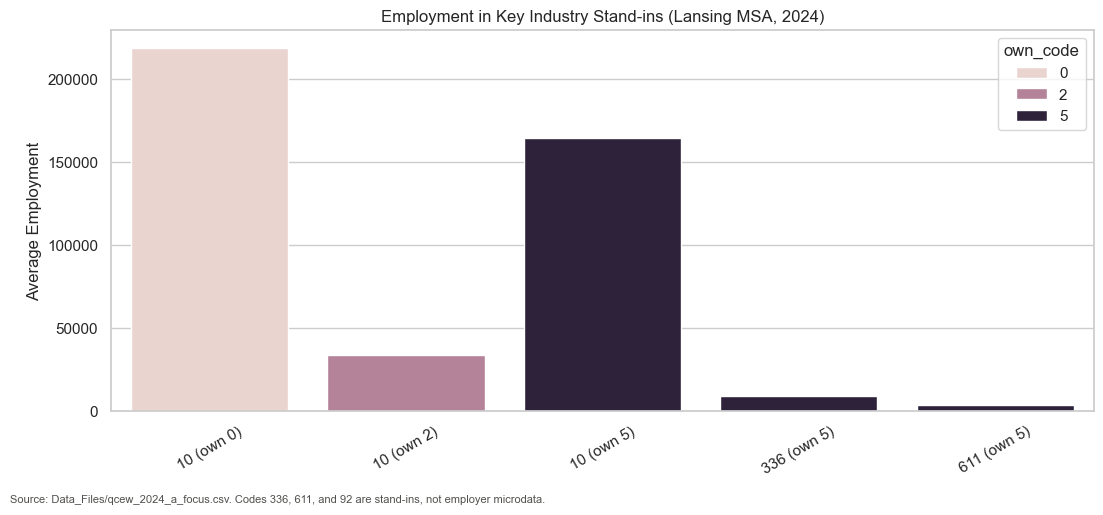

Exported      figures/03_industry_standins.png


WindowsPath('C:/Users/swens/PycharmProjects/CMSE 495/NC3/figure_instructions/figures/03_industry_standins.png')

In [5]:
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(
    data=standins,
    x="label",
    y="annual_avg_emplvl",
    hue="own_code",
    dodge=False,
    ax=ax,
)
ax.set_title("Employment in Key Industry Stand-ins (Lansing MSA, 2024)")
ax.set_ylabel("Average Employment")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
source_note(fig, "Source: Data_Files/qcew_2024_a_focus.csv. Codes 336, 611, and 92 are stand-ins, not employer microdata.")
export(
    fig,
    "03_industry_standins",
    "2024 MSA employment for all-industry, transportation equipment, education, and public administration stand-ins.",
    "notebooks/baseline_visualizations.ipynb section 3; INSTALL.md demo chart 3.",
)


### Figure 4. Median household income by geography

**Used in:** `notebooks/baseline_visualizations.ipynb` section 4, and as the fourth chart of the `INSTALL.md` demo.

The estimate is ACS table `B19013` (median household income in 2024 dollars). One row per `geo_name`.


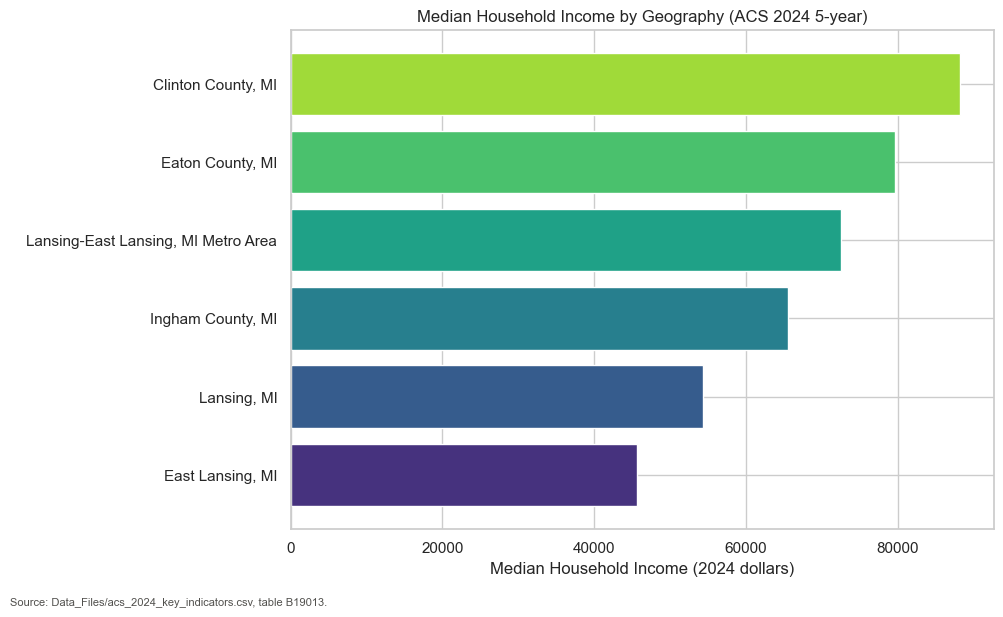

Exported      figures/04_median_income_by_geography.png


WindowsPath('C:/Users/swens/PycharmProjects/CMSE 495/NC3/figure_instructions/figures/04_median_income_by_geography.png')

In [6]:
plot_mhi = mhi.sort_values("estimate", ascending=True)
fig, ax = plt.subplots()
colors = sns.color_palette("viridis", len(plot_mhi))
ax.barh(plot_mhi["geo_name"], plot_mhi["estimate"], color=colors)
ax.set_title("Median Household Income by Geography (ACS 2024 5-year)")
ax.set_xlabel("Median Household Income (2024 dollars)")
ax.set_ylabel("")
fig.tight_layout()
source_note(fig, "Source: Data_Files/acs_2024_key_indicators.csv, table B19013.")
export(
    fig,
    "04_median_income_by_geography",
    "ACS 2024 5-year median household income for the counties, cities, and MSA in the extract.",
    "notebooks/baseline_visualizations.ipynb section 4; INSTALL.md demo chart 4.",
)


## 2. Partner-meeting figures

These charts appear in `notebooks/NC3_Partner_Meeting_Snapshot.ipynb` and `notebooks/NC3_Lansing_Findings_Correlation.ipynb`.
The meeting notebooks were written for a November 2026 discussion with the Lansing Growth Fund.
They display the charts in the notebook with Plotly and do not export files.

Two meeting charts were typed into the notebook as summaries:

- The annual unemployment chart in the partner snapshot lists hand-entered yearly rates.
- The ownership chart in that snapshot lists hand-entered magnitudes (Private 155,000, State Government 32,000, Local Government 18,000, Federal 2,000).

This file does not redraw those typed numbers. Figure 5 is the annual mean of the monthly LAUS series. October 2025 is a dash in the extract, so that month is dropped and the 2025 mean uses 11 months. 2026 is January through August. Figure 6 sums the 2024 QCEW ownership rows for Clinton, Eaton, and Ingham. The printed comparison under figure 5 shows the hand-entered meeting values next to the means, so a reviewer can see both.

The county income chart uses the same ACS cells the findings notebook quoted: Clinton $88,210, Eaton $79,597, Ingham $65,526.


Intermediate  intermediate/05_laus_annual_average.csv  (8 rows)
Annual mean from LAUS, next to the rate typed in the partner snapshot:
  Period  Unemployment Rate (%)  Months  Meeting notebook typed rate
    2019                   3.48      12                          3.6
    2020                   7.78      12                          8.5
    2021                   5.09      12                          5.1
    2022                   4.24      12                          4.2
    2023                   3.77      12                          3.9
    2024                   4.37      12                          4.3
    2025                   4.77      11                          4.8
2026 YTD                   4.53       8                          4.5


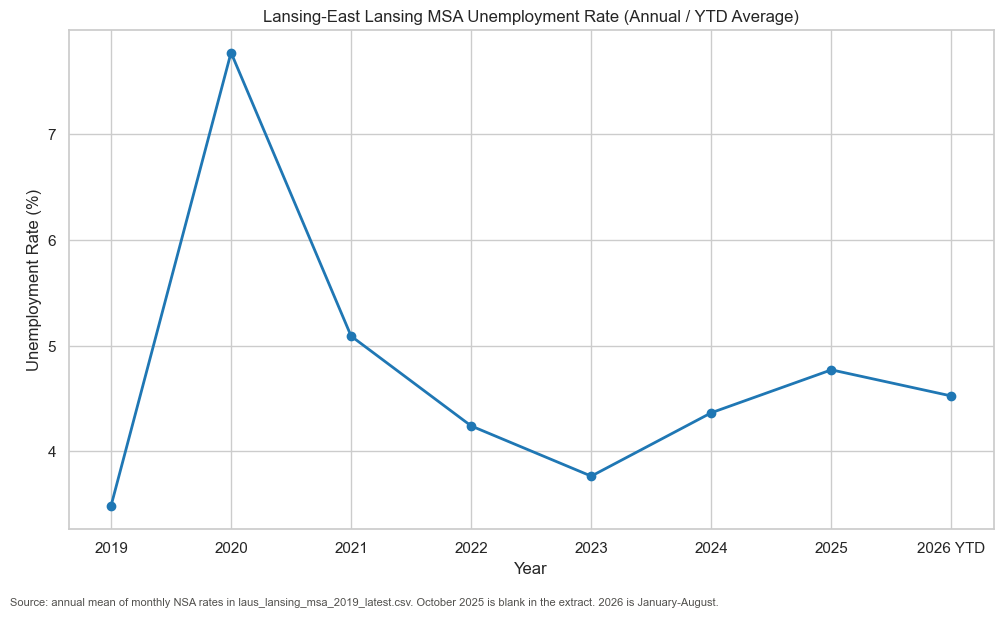

Exported      figures/05_laus_annual_average.png


WindowsPath('C:/Users/swens/PycharmProjects/CMSE 495/NC3/figure_instructions/figures/05_laus_annual_average.png')

In [7]:
annual_rows = []
for year, part in ur.groupby(ur["date"].dt.year):
    label = str(int(year))
    if int(year) == int(ur["date"].dt.year.max()) and len(part) < 12:
        label = f"{int(year)} YTD"
    annual_rows.append({
        "Period": label,
        "Unemployment Rate (%)": part["value"].mean(),
        "Months": len(part),
    })
annual = pd.DataFrame(annual_rows)
save_table(annual, "05_laus_annual_average")

# Values typed in NC3_Partner_Meeting_Snapshot.ipynb. Kept only for the comparison print.
meeting_typed = pd.DataFrame({
    "Period": ["2019", "2020", "2021", "2022", "2023", "2024", "2025", "2026 YTD"],
    "Meeting notebook typed rate": [3.6, 8.5, 5.1, 4.2, 3.9, 4.3, 4.8, 4.5],
})
comparison = annual.merge(meeting_typed, on="Period", how="left")
print("Annual mean from LAUS, next to the rate typed in the partner snapshot:")
print(comparison.round(2).to_string(index=False))

fig, ax = plt.subplots()
ax.plot(annual["Period"], annual["Unemployment Rate (%)"], marker="o", color="#1f77b4", linewidth=2)
ax.set_title("Lansing-East Lansing MSA Unemployment Rate (Annual / YTD Average)")
ax.set_xlabel("Year")
ax.set_ylabel("Unemployment Rate (%)")
fig.tight_layout()
source_note(fig, "Source: annual mean of monthly NSA rates in laus_lansing_msa_2019_latest.csv. October 2025 is blank in the extract. 2026 is January-August.")
export(
    fig,
    "05_laus_annual_average",
    "Annual mean unemployment rate. 2026 is the mean of the months present in the extract.",
    "notebooks/NC3_Partner_Meeting_Snapshot.ipynb labor-market section.",
)


### Figure 6. Tri-county employment by ownership

**Used in:** `notebooks/NC3_Partner_Meeting_Snapshot.ipynb`, employment section.

Each bar is the sum of Clinton, Eaton, and Ingham for industry code `10` and one ownership code. The label on the bar is that ownership's share of the four ownership groups. Figure 2 is the MSA version of this chart and is the install-demo figure. This one is the tri-county version used in the partner discussion.


Intermediate  intermediate/06_tricounty_ownership.csv  (4 rows)


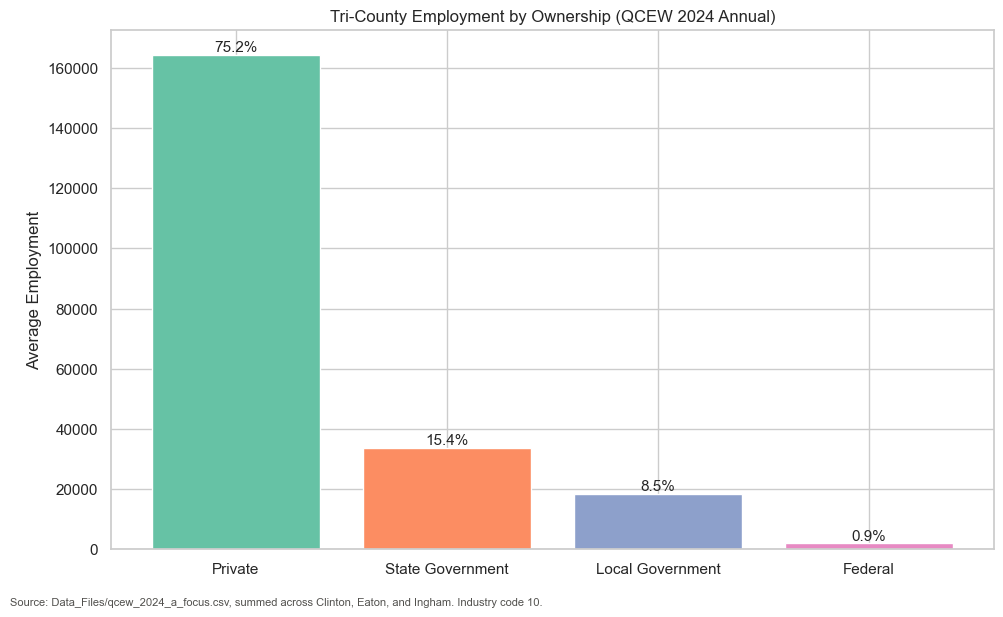

Exported      figures/06_tricounty_ownership.png


WindowsPath('C:/Users/swens/PycharmProjects/CMSE 495/NC3/figure_instructions/figures/06_tricounty_ownership.png')

In [8]:
tri_names = ["Clinton", "Eaton", "Ingham"]
tri_order = ["Private", "State Government", "Local Government", "Federal"]
tri_labels = {5: "Private", 2: "State Government", 3: "Local Government", 1: "Federal"}
tri_own = qcew[
    qcew["area_name"].isin(tri_names)
    & (qcew["industry_code"] == "10")
    & (qcew["own_code"].isin(tri_labels))
].copy()
tri_own["Ownership"] = tri_own["own_code"].map(tri_labels)
tri_own = (
    tri_own.groupby("Ownership", as_index=False)["annual_avg_emplvl"]
    .sum()
    .rename(columns={"annual_avg_emplvl": "Employment"})
)
tri_own["Share (%)"] = tri_own["Employment"] / tri_own["Employment"].sum() * 100
tri_own["Ownership"] = pd.Categorical(tri_own["Ownership"], categories=tri_order, ordered=True)
tri_own = tri_own.sort_values("Ownership")
save_table(tri_own, "06_tricounty_ownership")

fig, ax = plt.subplots()
bars = ax.bar(tri_own["Ownership"], tri_own["Employment"], color=sns.color_palette("Set2", len(tri_own)))
ax.set_title("Tri-County Employment by Ownership (QCEW 2024 Annual)")
ax.set_ylabel("Average Employment")
ax.set_xlabel("")
for bar, share in zip(bars, tri_own["Share (%)"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{share:.1f}%",
        ha="center",
        va="bottom",
    )
fig.tight_layout()
source_note(fig, "Source: Data_Files/qcew_2024_a_focus.csv, summed across Clinton, Eaton, and Ingham. Industry code 10.")
export(
    fig,
    "06_tricounty_ownership",
    "2024 tri-county average employment by ownership, with each group's share of the four groups.",
    "notebooks/NC3_Partner_Meeting_Snapshot.ipynb employment section.",
)


### Figure 7. Median household income by county

**Used in:** the partner snapshot and `notebooks/NC3_Lansing_Findings_Correlation.ipynb`.

Same `B19013` extract as figure 4, limited to Clinton, Eaton, and Ingham counties.


Intermediate  intermediate/07_county_median_income.csv  (3 rows)


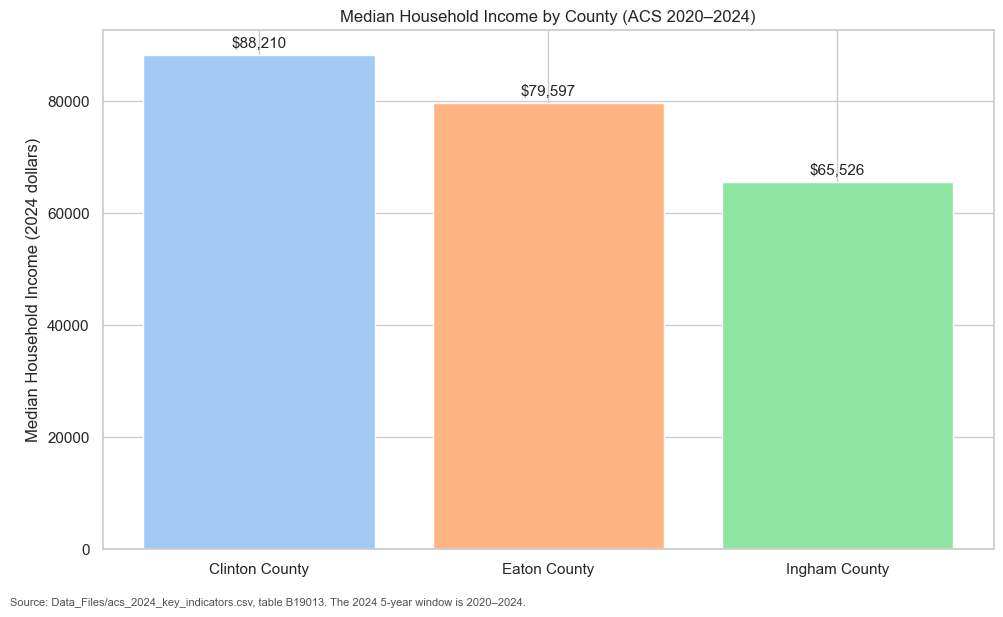

Exported      figures/07_county_median_income.png


WindowsPath('C:/Users/swens/PycharmProjects/CMSE 495/NC3/figure_instructions/figures/07_county_median_income.png')

In [9]:
county_mhi_names = ["Clinton County, MI", "Eaton County, MI", "Ingham County, MI"]
county_mhi = mhi[mhi["geo_name"].isin(county_mhi_names)].copy()
county_mhi["Geography"] = county_mhi["geo_name"].str.replace(" County, MI", " County", regex=False)
county_mhi = county_mhi.rename(columns={"estimate": "Median Household Income"})
save_table(county_mhi[["Geography", "Median Household Income"]], "07_county_median_income")

fig, ax = plt.subplots()
bars = ax.bar(
    county_mhi["Geography"],
    county_mhi["Median Household Income"],
    color=sns.color_palette("pastel", len(county_mhi)),
)
ax.set_title("Median Household Income by County (ACS 2020–2024)")
ax.set_ylabel("Median Household Income (2024 dollars)")
ax.set_xlabel("")
ax.bar_label(bars, fmt="${:,.0f}", padding=3)
fig.tight_layout()
source_note(fig, "Source: Data_Files/acs_2024_key_indicators.csv, table B19013. The 2024 5-year window is 2020–2024.")
export(
    fig,
    "07_county_median_income",
    "ACS 2024 5-year median household income for Clinton, Eaton, and Ingham counties.",
    "notebooks/NC3_Partner_Meeting_Snapshot.ipynb and notebooks/NC3_Lansing_Findings_Correlation.ipynb.",
)


## 3. GM footprint figures

These three charts are the figures in `notebooks/NC3_GM_Data_Correlation.ipynb`.
The findings notebook discusses the same employment, taxable-value, and parcel series.
Ultium Cell LLC is the former GM joint venture and is now LG Energy Solution. Rows for Ultium are not flagged `GM` in the taxpayer file, so they stay out of the GM total.

Inputs:

- `Data_Files/lansing_acfr_fy2025_principal_employers.csv` — ACFR FY2025 Table 15, transcribed from the statistical section
- `Data_Files/lansing_acfr_fy2025_principal_taxpayers.csv` — ACFR FY2025 Table 7
- `Data_Files/lansing_gm_area_parcels_values.csv` — City of Lansing BS&A parcel values for the assembly sites

The meeting notebooks typed the GM totals into a DataFrame. Those typed totals match these CSVs (GM employment 5,222 in 2016 and 4,549 in 2025; combined taxable value $59,302,202 in 2016 and $68,991,419 in 2025; Delta Township core parcel taxable value from $31,460,656 in 2023 to $34,977,290 in 2026). This notebook reads the CSVs.


Intermediate  intermediate/08_gm_regional_employment.csv  (2 rows)


 Year  Employees  Pct of Metro Employment  Metro Total Employment  Rank
 2016       5222                     2.28                  229466     4
 2025       4549                     2.15                  211208     4


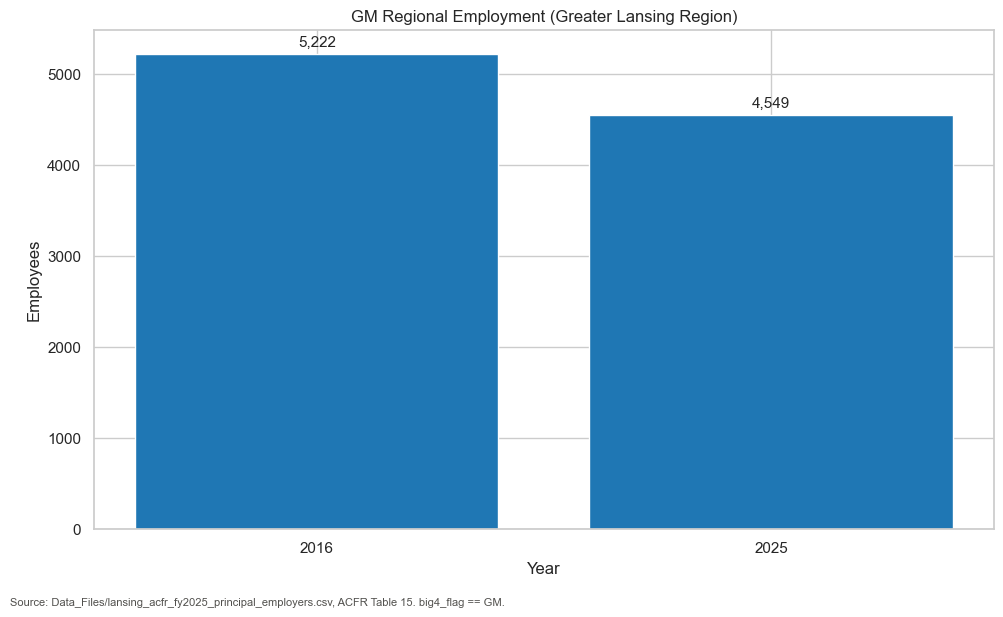

Exported      figures/08_gm_regional_employment.png


WindowsPath('C:/Users/swens/PycharmProjects/CMSE 495/NC3/figure_instructions/figures/08_gm_regional_employment.png')

In [10]:
employers = pd.read_csv(DATA_DIR / "lansing_acfr_fy2025_principal_employers.csv")
gm_emp = employers[employers["big4_flag"] == "GM"][
    ["year", "employees", "pct_of_metro_employment", "metro_total_employment", "rank_as_published"]
].sort_values("year")
gm_emp = gm_emp.rename(columns={
    "year": "Year",
    "employees": "Employees",
    "pct_of_metro_employment": "Pct of Metro Employment",
    "metro_total_employment": "Metro Total Employment",
    "rank_as_published": "Rank",
})
save_table(gm_emp, "08_gm_regional_employment")
print(gm_emp.to_string(index=False))

fig, ax = plt.subplots()
bars = ax.bar(gm_emp["Year"].astype(str), gm_emp["Employees"], color="#1f77b4")
ax.set_title("GM Regional Employment (Greater Lansing Region)")
ax.set_xlabel("Year")
ax.set_ylabel("Employees")
ax.bar_label(bars, fmt="{:,.0f}", padding=3)
fig.tight_layout()
source_note(fig, "Source: Data_Files/lansing_acfr_fy2025_principal_employers.csv, ACFR Table 15. big4_flag == GM.")
export(
    fig,
    "08_gm_regional_employment",
    "GM employees in the Greater Lansing Region, 2016 and 2025, from ACFR Table 15.",
    "notebooks/NC3_GM_Data_Correlation.ipynb section 1.",
)


Intermediate  intermediate/09_gm_combined_taxable_value.csv  (2 rows)
GM rows included in the combined total:
 tax_year           taxpayer  taxable_assessed_value  rank
     2016 General Motors LLC                59302202     1
     2025 General Motors LLC                49069602     3
     2025 General Motors Co.                19921817     9


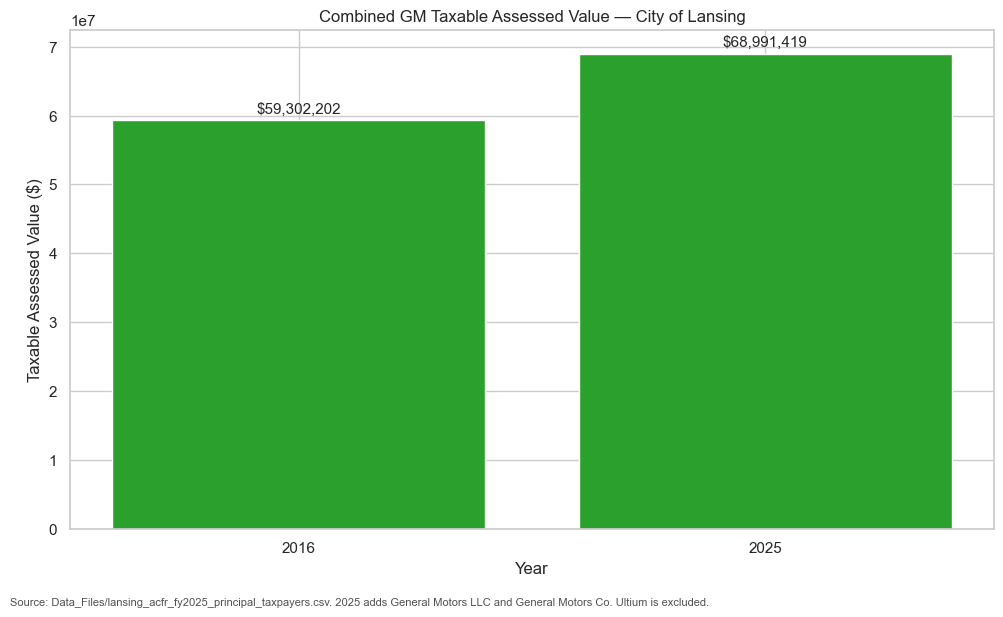

Exported      figures/09_gm_combined_taxable_value.png


WindowsPath('C:/Users/swens/PycharmProjects/CMSE 495/NC3/figure_instructions/figures/09_gm_combined_taxable_value.png')

In [11]:
taxpayers = pd.read_csv(DATA_DIR / "lansing_acfr_fy2025_principal_taxpayers.csv")
gm_tax = taxpayers[taxpayers["big4_flag"] == "GM"].copy()
gm_combined = (
    gm_tax.groupby("tax_year", as_index=False)["taxable_assessed_value"]
    .sum()
    .rename(columns={"tax_year": "Year", "taxable_assessed_value": "Combined GM Taxable Value"})
)
gm_combined["Year"] = gm_combined["Year"].astype(str)
save_table(gm_combined, "09_gm_combined_taxable_value")
print("GM rows included in the combined total:")
print(gm_tax[["tax_year", "taxpayer", "taxable_assessed_value", "rank"]].sort_values(["tax_year", "rank"]).to_string(index=False))

fig, ax = plt.subplots()
bars = ax.bar(gm_combined["Year"], gm_combined["Combined GM Taxable Value"], color="#2ca02c")
ax.set_title("Combined GM Taxable Assessed Value — City of Lansing")
ax.set_xlabel("Year")
ax.set_ylabel("Taxable Assessed Value ($)")
ax.bar_label(bars, fmt="${:,.0f}", padding=3)
fig.tight_layout()
source_note(fig, "Source: Data_Files/lansing_acfr_fy2025_principal_taxpayers.csv. 2025 adds General Motors LLC and General Motors Co. Ultium is excluded.")
export(
    fig,
    "09_gm_combined_taxable_value",
    "Combined taxable assessed value of GM entities on ACFR Table 7. Ultium / LG Energy Solution is excluded.",
    "notebooks/NC3_GM_Data_Correlation.ipynb section 2 and notebooks/NC3_Lansing_Findings_Correlation.ipynb.",
)


Intermediate  intermediate/10_delta_assembly_taxable_value.csv  (12 rows)
 Tax Year  Taxable Value                                          address
     2023       31460656 8001 Davis Hwy (Lansing Delta Township Assembly)
     2023              0                   8001 Davis Hwy (LDT equipment)
     2023        3649400                8001 Davis Hwy (LDT IFT building)
     2024              0                   8001 Davis Hwy (LDT equipment)
     2024        3831870                8001 Davis Hwy (LDT IFT building)
     2024       33033688 8001 Davis Hwy (Lansing Delta Township Assembly)
     2025              0                   8001 Davis Hwy (LDT equipment)
     2025       34057732 8001 Davis Hwy (Lansing Delta Township Assembly)
     2025        3950657                8001 Davis Hwy (LDT IFT building)
     2026       34977290 8001 Davis Hwy (Lansing Delta Township Assembly)
     2026              0                   8001 Davis Hwy (LDT equipment)
     2026        4057324              

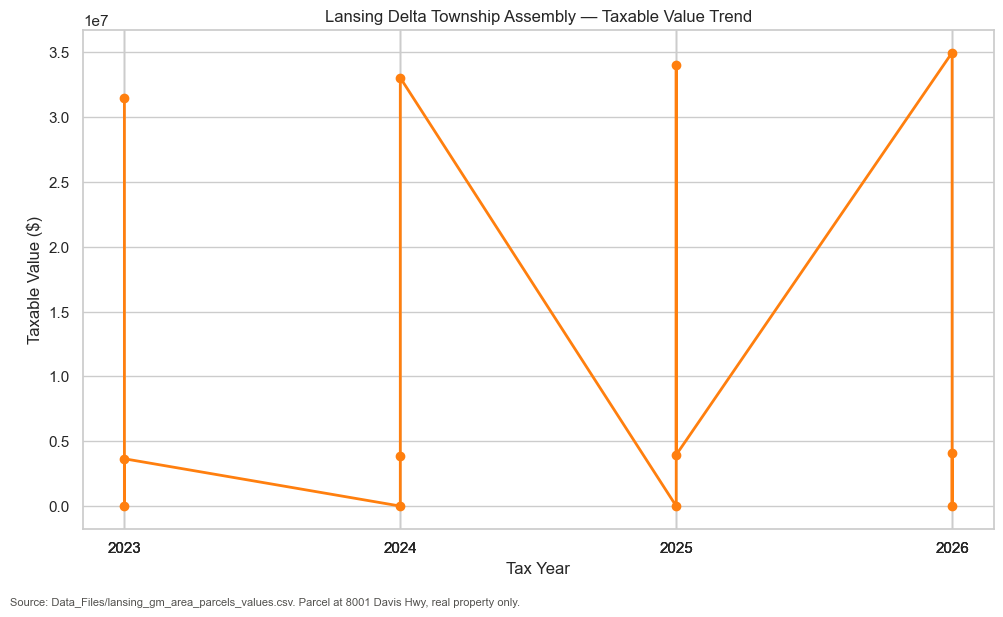

Exported      figures/10_delta_assembly_taxable_value.png


WindowsPath('C:/Users/swens/PycharmProjects/CMSE 495/NC3/figure_instructions/figures/10_delta_assembly_taxable_value.png')

In [12]:
parcels = pd.read_csv(DATA_DIR / "lansing_gm_area_parcels_values.csv")
delta = parcels[
    parcels["address"].astype(str).str.contains("8001 Davis", case=False, na=False)
    & (parcels["big4_flag"] == "GM")
][["tax_year", "taxable_value", "address"]].sort_values("tax_year")
delta = delta.rename(columns={"tax_year": "Tax Year", "taxable_value": "Taxable Value"})
save_table(delta, "10_delta_assembly_taxable_value")
print(delta.to_string(index=False))

fig, ax = plt.subplots()
ax.plot(delta["Tax Year"], delta["Taxable Value"], marker="o", color="#ff7f0e", linewidth=2)
ax.set_title("Lansing Delta Township Assembly — Taxable Value Trend")
ax.set_xlabel("Tax Year")
ax.set_ylabel("Taxable Value ($)")
ax.set_xticks(delta["Tax Year"].tolist())
fig.tight_layout()
source_note(fig, "Source: Data_Files/lansing_gm_area_parcels_values.csv. Parcel at 8001 Davis Hwy, real property only.")
export(
    fig,
    "10_delta_assembly_taxable_value",
    "Taxable value of the core real-property parcel at the Lansing Delta Township Assembly, 2023–2026.",
    "notebooks/NC3_GM_Data_Correlation.ipynb section 3 and notebooks/NC3_Lansing_Findings_Correlation.ipynb section 6.",
)


## 4. Tri-county findings figures

These charts are sections 3–5 of `notebooks/NC3_Lansing_Findings_Correlation.ipynb`.
The findings notebook built one county table by hand. This notebook builds that table from the ACS and QCEW extracts.

For each county the table uses:

- Median household income: ACS `B19013`
- Poverty rate: ACS `B17001` people below poverty (`B17001002`) divided by the poverty universe (`B17001001`)
- Owner-occupied share: ACS `B25003` owner-occupied (`B25003002`) divided by occupied units (`B25003001`)
- Population, used only to size the points: ACS `B01003`
- State-government share: QCEW ownership code 2, industry `10`, divided by ownership code 0, industry `10`
- NAICS 336 share: QCEW private ownership (code 5), industry `336`, divided by ownership code 0, industry `10`

The findings notebook also included an ACS manufacturing-employment share that was typed into the cell. That count is not a column in `acs_2024_key_indicators.csv`, so the heatmap here uses the five measures listed above. With three counties, read the correlations as a description of this table, not as a stable coefficient.

QCEW cells that match the findings notebook: state government employment is 15 in Clinton, 2,351 in Eaton, and 31,363 in Ingham. Private NAICS 336 employment is 341, 4,845, and 3,515.


In [13]:
def acs_value(table_id, column_id, geo_name):
    rows = acs[
        (acs["table_id"] == table_id)
        & (acs["column_id"] == column_id)
        & (acs["geo_name"] == geo_name)
    ]
    if rows.empty:
        raise ValueError(f"No ACS row for {table_id} {column_id} {geo_name}")
    return float(rows["estimate"].iloc[0])


def qcew_jobs(area_name, own_code, industry_code):
    rows = qcew[
        (qcew["area_name"] == area_name)
        & (qcew["own_code"] == own_code)
        & (qcew["industry_code"] == industry_code)
    ]
    if rows.empty:
        raise ValueError(f"No QCEW row for {area_name} own {own_code} industry {industry_code}")
    return float(rows["annual_avg_emplvl"].iloc[0])


county_geos = [
    ("Clinton County", "Clinton County, MI", "Clinton"),
    ("Eaton County", "Eaton County, MI", "Eaton"),
    ("Ingham County", "Ingham County, MI", "Ingham"),
]
county_rows = []
for label, geo_name, area_name in county_geos:
    poverty_universe = acs_value("B17001", "B17001001", geo_name)
    below_poverty = acs_value("B17001", "B17001002", geo_name)
    occupied = acs_value("B25003", "B25003001", geo_name)
    owner = acs_value("B25003", "B25003002", geo_name)
    total_jobs = qcew_jobs(area_name, 0, "10")
    state_jobs = qcew_jobs(area_name, 2, "10")
    naics_336 = qcew_jobs(area_name, 5, "336")
    county_rows.append({
        "Geography": label,
        "Population": acs_value("B01003", "B01003001", geo_name),
        "Median HH Income": acs_value("B19013", "B19013001", geo_name),
        "Poverty Rate (%)": below_poverty / poverty_universe * 100,
        "Owner-Occupied (%)": owner / occupied * 100,
        "State Gov Share (%)": state_jobs / total_jobs * 100,
        "NAICS 336 Share (%)": naics_336 / total_jobs * 100,
    })
counties = pd.DataFrame(county_rows)
save_table(counties, "11_county_snapshot")
print(counties.round(1).to_string(index=False))


Intermediate  intermediate/11_county_snapshot.csv  (3 rows)
     Geography  Population  Median HH Income  Poverty Rate (%)  Owner-Occupied (%)  State Gov Share (%)  NAICS 336 Share (%)
Clinton County     79626.0           88210.0               9.7                82.2                  0.1                  1.8
  Eaton County    109130.0           79597.0               8.3                74.2                  5.3                 10.9
 Ingham County    283913.0           65526.0              16.7                59.5                 20.2                  2.3


### Figure 11. City, county, and MSA median income

**Used in:** `notebooks/NC3_Lansing_Findings_Correlation.ipynb` section 3.

Labels match that notebook: Lansing city, East Lansing city, Ingham County, and MSA.


Intermediate  intermediate/11_city_county_msa_income.csv  (4 rows)


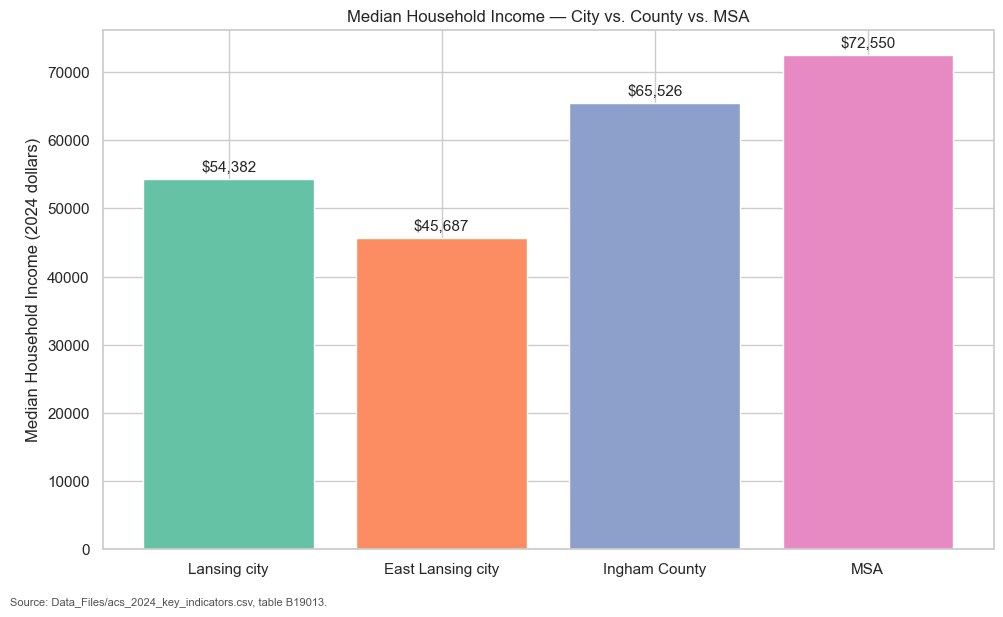

Exported      figures/11_city_county_msa_income.png


WindowsPath('C:/Users/swens/PycharmProjects/CMSE 495/NC3/figure_instructions/figures/11_city_county_msa_income.png')

In [14]:
city_map = [
    ("Lansing city", "Lansing, MI"),
    ("East Lansing city", "East Lansing, MI"),
    ("Ingham County", "Ingham County, MI"),
    ("MSA", "Lansing-East Lansing, MI Metro Area"),
]
city_rows = []
for label, geo_name in city_map:
    city_rows.append({
        "Geography": label,
        "Median HH Income": acs_value("B19013", "B19013001", geo_name),
    })
cities = pd.DataFrame(city_rows)
save_table(cities, "11_city_county_msa_income")

fig, ax = plt.subplots()
bars = ax.bar(cities["Geography"], cities["Median HH Income"], color=sns.color_palette("Set2", len(cities)))
ax.set_title("Median Household Income — City vs. County vs. MSA")
ax.set_ylabel("Median Household Income (2024 dollars)")
ax.set_xlabel("")
ax.bar_label(bars, fmt="${:,.0f}", padding=3)
fig.tight_layout()
source_note(fig, "Source: Data_Files/acs_2024_key_indicators.csv, table B19013.")
export(
    fig,
    "11_city_county_msa_income",
    "Median household income for Lansing, East Lansing, Ingham County, and the MSA.",
    "notebooks/NC3_Lansing_Findings_Correlation.ipynb section 3.",
)


### Figure 12. Correlation heatmap

**Used in:** `notebooks/NC3_Lansing_Findings_Correlation.ipynb` section 4.

Pearson correlations across the three county rows from the table in the previous section. n = 3.


Intermediate  intermediate/12_county_correlation.csv  (5 rows)
                     Median HH Income  Poverty Rate (%)  Owner-Occupied (%)  State Gov Share (%)  NAICS 336 Share (%)
Median HH Income                 1.00             -0.86                1.00                -0.99                 0.10
Poverty Rate (%)                -0.86              1.00               -0.87                 0.92                -0.59
Owner-Occupied (%)               1.00             -0.87                1.00                -0.99                 0.13
State Gov Share (%)             -0.99              0.92               -0.99                 1.00                -0.23
NAICS 336 Share (%)              0.10             -0.59                0.13                -0.23                 1.00


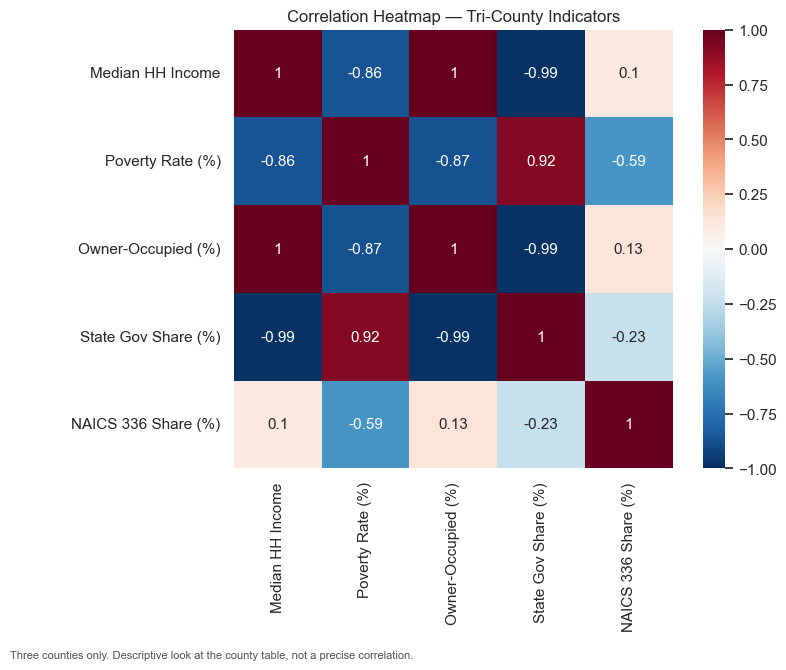

Exported      figures/12_county_correlation.png


WindowsPath('C:/Users/swens/PycharmProjects/CMSE 495/NC3/figure_instructions/figures/12_county_correlation.png')

In [15]:
corr_cols = [
    "Median HH Income",
    "Poverty Rate (%)",
    "Owner-Occupied (%)",
    "State Gov Share (%)",
    "NAICS 336 Share (%)",
]
corr = counties[corr_cols].corr().round(2)
save_table(corr.reset_index().rename(columns={"index": "measure"}), "12_county_correlation")
print(corr.to_string())

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Correlation Heatmap — Tri-County Indicators")
fig.tight_layout()
source_note(fig, "Three counties only. Descriptive look at the county table, not a precise correlation.")
export(
    fig,
    "12_county_correlation",
    "Pearson correlations among income, poverty, homeownership, state-government share, and NAICS 336 share. n = 3.",
    "notebooks/NC3_Lansing_Findings_Correlation.ipynb section 4.",
)


### Figures 13 and 14. Employment mix vs. resident outcomes

**Used in:** `notebooks/NC3_Lansing_Findings_Correlation.ipynb` section 5.

Point area is county population. Eaton has the largest NAICS 336 share. Ingham has the largest state-government share.


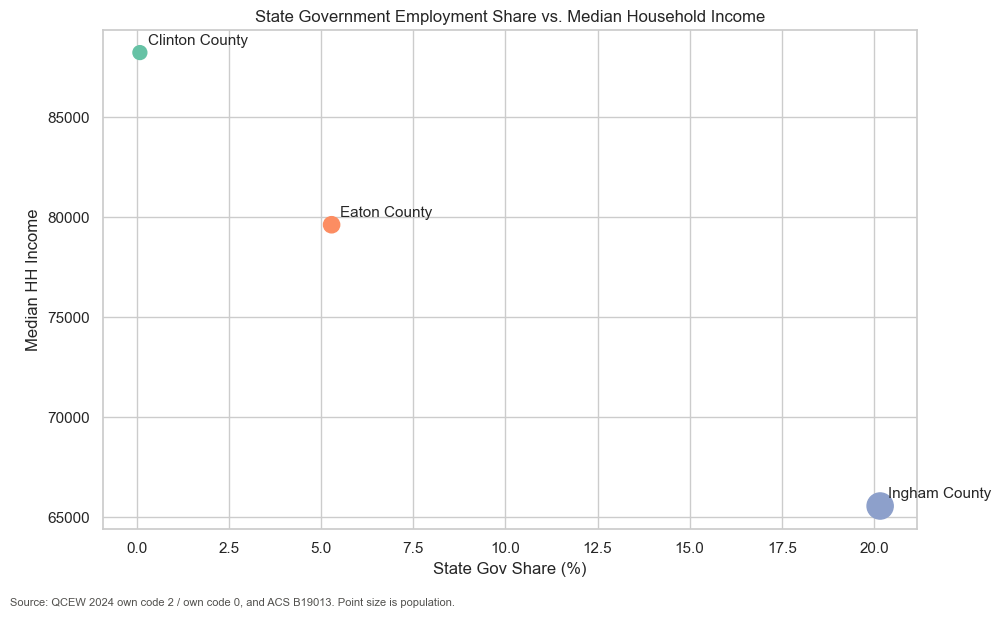

Exported      figures/13_state_gov_share_vs_income.png


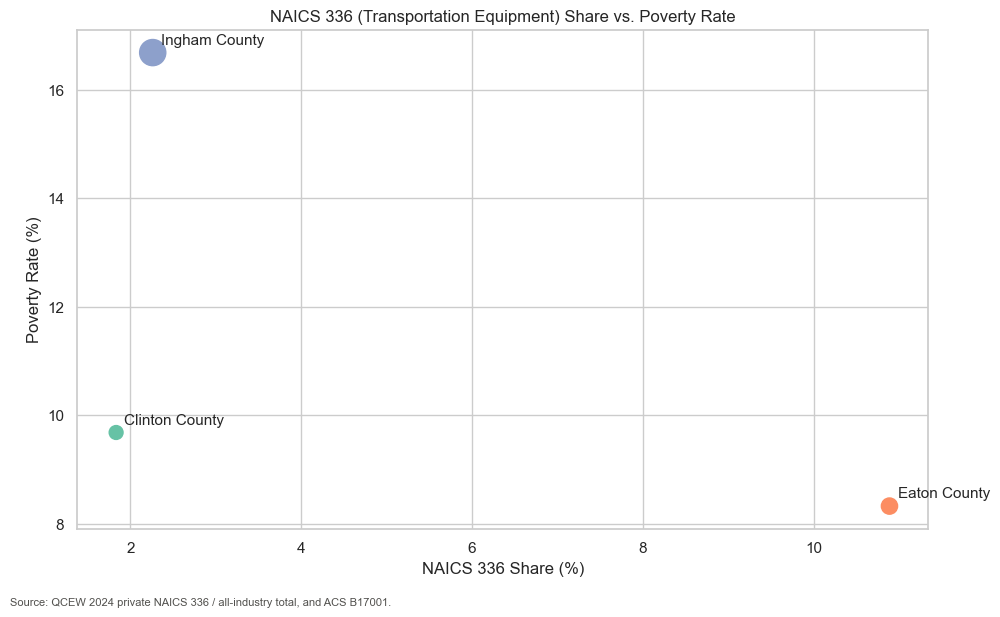

Exported      figures/14_naics336_share_vs_poverty.png


WindowsPath('C:/Users/swens/PycharmProjects/CMSE 495/NC3/figure_instructions/figures/14_naics336_share_vs_poverty.png')

In [16]:
fig, ax = plt.subplots()
ax.scatter(
    counties["State Gov Share (%)"],
    counties["Median HH Income"],
    s=counties["Population"] / 800,
    c=sns.color_palette("Set2", len(counties)),
)
for _, row in counties.iterrows():
    ax.annotate(row["Geography"], (row["State Gov Share (%)"], row["Median HH Income"]), textcoords="offset points", xytext=(6, 6))
ax.set_title("State Government Employment Share vs. Median Household Income")
ax.set_xlabel("State Gov Share (%)")
ax.set_ylabel("Median HH Income")
fig.tight_layout()
source_note(fig, "Source: QCEW 2024 own code 2 / own code 0, and ACS B19013. Point size is population.")
export(
    fig,
    "13_state_gov_share_vs_income",
    "County state-government employment share against median household income.",
    "notebooks/NC3_Lansing_Findings_Correlation.ipynb section 5.",
)

fig, ax = plt.subplots()
ax.scatter(
    counties["NAICS 336 Share (%)"],
    counties["Poverty Rate (%)"],
    s=counties["Population"] / 800,
    c=sns.color_palette("Set2", len(counties)),
)
for _, row in counties.iterrows():
    ax.annotate(row["Geography"], (row["NAICS 336 Share (%)"], row["Poverty Rate (%)"]), textcoords="offset points", xytext=(6, 6))
ax.set_title("NAICS 336 (Transportation Equipment) Share vs. Poverty Rate")
ax.set_xlabel("NAICS 336 Share (%)")
ax.set_ylabel("Poverty Rate (%)")
fig.tight_layout()
source_note(fig, "Source: QCEW 2024 private NAICS 336 / all-industry total, and ACS B17001.")
export(
    fig,
    "14_naics336_share_vs_poverty",
    "County transportation-equipment employment share against the ACS poverty rate.",
    "notebooks/NC3_Lansing_Findings_Correlation.ipynb section 5.",
)


## 5. Tract mismatch figures

These two charts are the figures in `notebooks/NC3_Tract_Mismatch_Snapshot.ipynb`.
That notebook loads `Data_Files/acs_tract_2020_2024.csv` and ranks tracts. It displays the bars with Plotly. This notebook writes PNGs of the same rankings.

Poverty rate is `below_poverty / poverty_universe * 100`, which is the calculation in the tract notebook. Tracts with a missing median household income are dropped before the lowest-income ranking. Census suppresses that median in some very small tracts.


Intermediate  intermediate/15_top_tracts_by_poverty.csv  (10 rows)


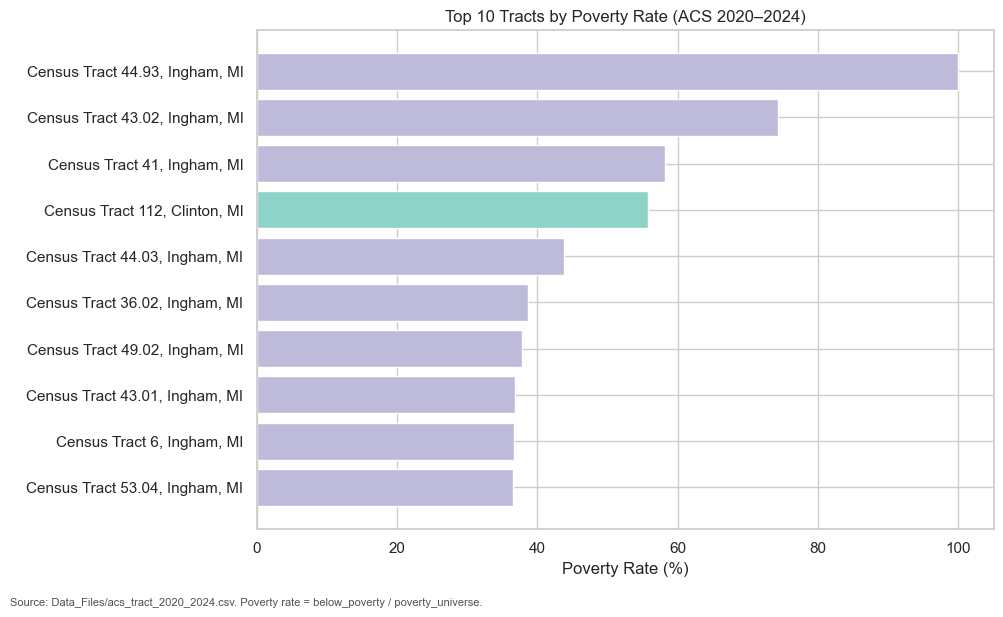

Exported      figures/15_top_tracts_by_poverty.png
Intermediate  intermediate/16_lowest_income_tracts.csv  (10 rows)


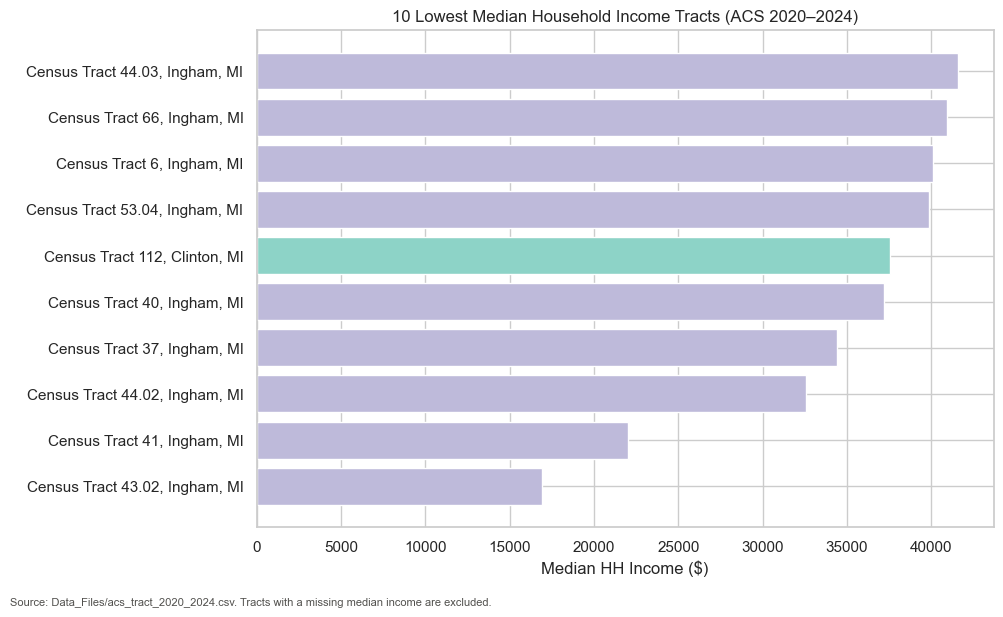

Exported      figures/16_lowest_income_tracts.png


WindowsPath('C:/Users/swens/PycharmProjects/CMSE 495/NC3/figure_instructions/figures/16_lowest_income_tracts.png')

In [17]:
tracts = pd.read_csv(DATA_DIR / "acs_tract_2020_2024.csv", dtype={"geoid": str})
tracts["poverty_rate"] = tracts["below_poverty"] / tracts["poverty_universe"] * 100
high_pov = tracts.nlargest(10, "poverty_rate")[
    ["NAME", "county_name", "poverty_rate", "median_hh_income", "population"]
].sort_values("poverty_rate", ascending=True)
save_table(high_pov, "15_top_tracts_by_poverty")

fig, ax = plt.subplots(figsize=(10, 6))
colors = high_pov["county_name"].map({"Clinton": "#8dd3c7", "Eaton": "#ffffb3", "Ingham": "#bebada"})
ax.barh(high_pov["NAME"], high_pov["poverty_rate"], color=colors)
ax.set_title("Top 10 Tracts by Poverty Rate (ACS 2020–2024)")
ax.set_xlabel("Poverty Rate (%)")
ax.set_ylabel("")
fig.tight_layout()
source_note(fig, "Source: Data_Files/acs_tract_2020_2024.csv. Poverty rate = below_poverty / poverty_universe.")
export(
    fig,
    "15_top_tracts_by_poverty",
    "Ten tri-county tracts with the highest ACS 2020–2024 poverty rates.",
    "notebooks/NC3_Tract_Mismatch_Snapshot.ipynb.",
)

low_inc = (
    tracts.dropna(subset=["median_hh_income"])
    .nsmallest(10, "median_hh_income")[
        ["NAME", "county_name", "median_hh_income", "poverty_rate", "population"]
    ]
    .sort_values("median_hh_income", ascending=True)
)
save_table(low_inc, "16_lowest_income_tracts")

fig, ax = plt.subplots(figsize=(10, 6))
colors = low_inc["county_name"].map({"Clinton": "#8dd3c7", "Eaton": "#ffffb3", "Ingham": "#bebada"})
ax.barh(low_inc["NAME"], low_inc["median_hh_income"], color=colors)
ax.set_title("10 Lowest Median Household Income Tracts (ACS 2020–2024)")
ax.set_xlabel("Median HH Income ($)")
ax.set_ylabel("")
fig.tight_layout()
source_note(fig, "Source: Data_Files/acs_tract_2020_2024.csv. Tracts with a missing median income are excluded.")
export(
    fig,
    "16_lowest_income_tracts",
    "Ten tri-county tracts with the lowest ACS 2020–2024 median household income.",
    "notebooks/NC3_Tract_Mismatch_Snapshot.ipynb.",
)


## 6. Scorecard figures from stored results

These five charts are the figures in the scorecard notebooks:

- `Individual_TeamMember_files/wangz153/01_footprint.ipynb` — figures 17 and 18
- `Individual_TeamMember_files/wangz153/02_retention.ipynb` — figure 19
- `Individual_TeamMember_files/wangz153/03_benefit.ipynb` — figures 20 and 21

They are the charts intended for the scorecard section of the report. The notebooks draw them inline and do not export PNGs. The plotting code below follows those cells, including the colors from `nc3_helpers.py`.

**Fast path (use this for review).** Read the CSVs already stored in `Individual_TeamMember_files/wangz153/outputs/`. No download and no multi-minute join.

| Stored file | Figure |
| --- | --- |
| `outputs/footprint_v0_2025.csv` | 17. Employment range |
| `outputs/footprint_timeseries_2019_2025.csv` | 18. Index, 2019 = 100 |
| `outputs/retention_v0_wages.csv` | 19. Local resident capture |
| `outputs/benefit_v0_site_neighborhoods.csv` | 20. Poverty near sites |
| `outputs/benefit_v0_tracts.csv` | 21. Jobs vs. poverty |

**Full rebuild, if you want to regenerate those CSVs.** Run all cells in `01_footprint.ipynb`, then `02_retention.ipynb`, then `03_benefit.ipynb`. They import `nc3_helpers.py` from the same folder and read `Data_Files/`. Notebook 02 reads the committed LODES aggregate `Data_Files/lodes_od_tri_workplace_2021_agg.csv.gz`. That step is the slow one. After those notebooks finish, re-run this notebook. You do not need a Census API key for that rebuild.

Figure 21 also uses tract latitude and longitude stored on `benefit_v0_tracts.csv`, and the site coordinates hardcoded in `03_benefit.ipynb` (copied below as `SITES`). A tract is "near" a site when its center is within 2 km, or it is one of the three closest non-student tracts if fewer than three fall inside 2 km. Student-dominated tracts are those with `student_share > 40`. Tracts with fewer than 200 residents are left off the scatter. The dashed horizontal line is the pooled poverty rate from `acs_tract_2020_2024.csv` (`sum of below_poverty / sum of poverty_universe`), which is the `REGION_POV` line in the benefit notebook. The dashed vertical line is 100 jobs per 100 residents.


Intermediate  intermediate/17_big4_employment_range.csv  (4 rows)


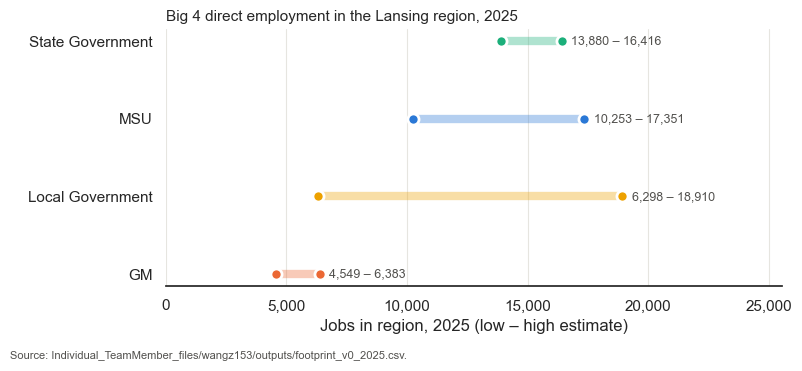

Exported      figures/17_big4_employment_range.png


WindowsPath('C:/Users/swens/PycharmProjects/CMSE 495/NC3/figure_instructions/figures/17_big4_employment_range.png')

In [18]:
sns.set_theme(style="white")
plt.rcParams["axes.grid"] = False

footprint = pd.read_csv(SCORECARD_DIR / "footprint_v0_2025.csv").set_index("institution")
order = footprint.sort_values("midpoint").index.tolist()
save_table(footprint.loc[order].reset_index(), "17_big4_employment_range")

fig, ax = plt.subplots(figsize=(8, 3.6))
for i, inst in enumerate(order):
    lo = footprint.loc[inst, "low"]
    hi = footprint.loc[inst, "high"]
    color = BIG4_COLORS[inst]
    ax.plot([lo, hi], [i, i], color=color, lw=6, solid_capstyle="round", alpha=0.35)
    ax.plot([lo, hi], [i, i], "o", color=color, ms=8, mec="white", mew=2)
    ax.text(hi + 400, i, f"{lo:,.0f} – {hi:,.0f}", va="center", fontsize=9, color="#52514e")
ax.set_yticks(range(len(order)), order)
ax.set_xlabel("Jobs in region, 2025 (low – high estimate)")
ax.set_xlim(0, footprint["high"].max() * 1.35)
ax.xaxis.set_major_formatter(lambda value, _pos: f"{value:,.0f}")
for spine in ("top", "right", "left"):
    ax.spines[spine].set_visible(False)
ax.grid(axis="x", color="#e6e5e0", lw=0.8)
ax.set_axisbelow(True)
ax.set_title("Big 4 direct employment in the Lansing region, 2025", loc="left", fontsize=11)
fig.tight_layout()
source_note(fig, "Source: Individual_TeamMember_files/wangz153/outputs/footprint_v0_2025.csv.")
export(
    fig,
    "17_big4_employment_range",
    "Low and high public estimates of 2025 employment for MSU, GM, state government, and local government.",
    "Individual_TeamMember_files/wangz153/01_footprint.ipynb.",
)


Intermediate  intermediate/18_employment_index_2019.csv  (7 rows)


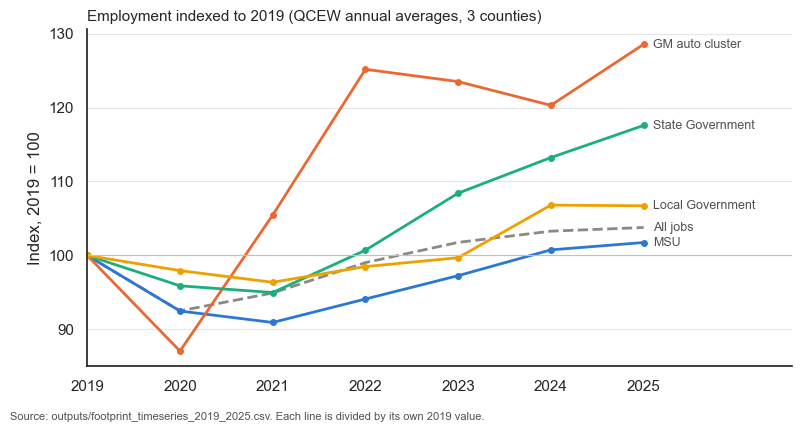

Exported      figures/18_employment_index_2019.png


WindowsPath('C:/Users/swens/PycharmProjects/CMSE 495/NC3/figure_instructions/figures/18_employment_index_2019.png')

In [19]:
trend = pd.read_csv(SCORECARD_DIR / "footprint_timeseries_2019_2025.csv")
trend["year"] = trend["year"].astype(int)
trend = trend.set_index("year")


def index_to(series, base_year):
    """Rebase a year-indexed series so base_year = 100. Same helper as nc3_helpers.index_to."""
    base = series.get(base_year, np.nan)
    if pd.notna(base) and base:
        return series / base * 100
    return series * np.nan


series = {
    "MSU": ("MSU (QCEW residual)", BIG4_COLORS["MSU"]),
    "GM auto cluster": ("GM auto cluster (336)", BIG4_COLORS["GM"]),
    "State Government": ("State Gov (own2 PA)", BIG4_COLORS["State Government"]),
    "Local Government": ("Local Gov core (own3 PA)", BIG4_COLORS["Local Government"]),
}
indexed = pd.DataFrame({"All jobs": index_to(trend["Region, all jobs"], 2019)})
for label, (column, _color) in series.items():
    indexed[label] = index_to(trend[column], 2019)
save_table(indexed.reset_index(), "18_employment_index_2019")

fig, ax = plt.subplots(figsize=(8, 4.2))
region_index = indexed["All jobs"]
ax.plot(region_index.index, region_index, color=REGION_COLOR, lw=2, ls="--")
ax.text(2025.1, region_index.loc[2025], "All jobs", va="center", fontsize=9, color="#52514e")
for label, (_column, color) in series.items():
    values = indexed[label]
    ax.plot(values.index, values, color=color, lw=2, marker="o", ms=4)
    ax.text(2025.1, values.loc[2025], label, va="center", fontsize=9, color="#52514e")
ax.axhline(100, color="#c3c2b7", lw=0.8)
ax.set_xlim(2019, 2026.6)
ax.set_xticks(range(2019, 2026))
ax.set_ylabel("Index, 2019 = 100")
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
ax.grid(axis="y", color="#e6e5e0", lw=0.8)
ax.set_axisbelow(True)
ax.set_title("Employment indexed to 2019 (QCEW annual averages, 3 counties)", loc="left", fontsize=11)
fig.tight_layout()
source_note(fig, "Source: outputs/footprint_timeseries_2019_2025.csv. Each line is divided by its own 2019 value.")
export(
    fig,
    "18_employment_index_2019",
    "QCEW employment indexed to 2019 for the region and for four Big 4 series.",
    "Individual_TeamMember_files/wangz153/01_footprint.ipynb section 4.",
)


Intermediate  intermediate/19_local_resident_capture.csv  (4 rows)


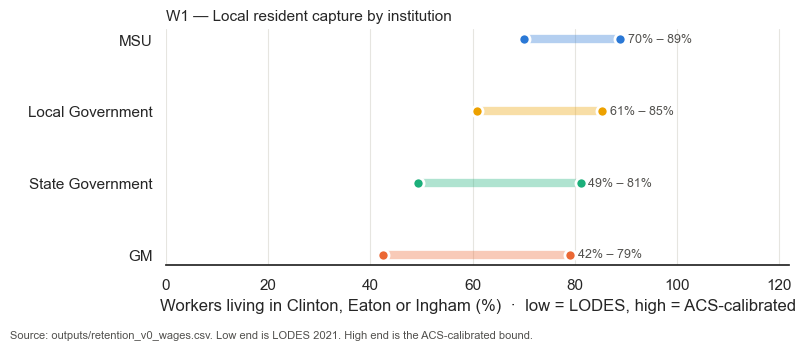

Exported      figures/19_local_resident_capture.png


WindowsPath('C:/Users/swens/PycharmProjects/CMSE 495/NC3/figure_instructions/figures/19_local_resident_capture.png')

In [20]:
wages = pd.read_csv(SCORECARD_DIR / "retention_v0_wages.csv").set_index("institution")
capture_cols = ["W1 low (LODES raw) %", "W1 high (ACS-calibrated) %"]
capture = wages[capture_cols].copy()
capture_order = capture.sort_values("W1 high (ACS-calibrated) %").index.tolist()
save_table(capture.loc[capture_order].reset_index(), "19_local_resident_capture")

fig, ax = plt.subplots(figsize=(8, 3.4))
for i, inst in enumerate(capture_order):
    lo = capture.loc[inst, "W1 low (LODES raw) %"]
    hi = capture.loc[inst, "W1 high (ACS-calibrated) %"]
    color = BIG4_COLORS[inst]
    ax.plot([lo, hi], [i, i], color=color, lw=6, alpha=0.35, solid_capstyle="round")
    ax.plot([lo, hi], [i, i], "o", color=color, ms=8, mec="white", mew=2)
    ax.text(hi + 1.5, i, f"{lo:.0f}% – {hi:.0f}%", va="center", fontsize=9, color="#52514e")
ax.set_yticks(range(len(capture_order)), capture_order)
ax.set_xlim(0, 122)
ax.set_xlabel("Workers living in Clinton, Eaton or Ingham (%)  ·  low = LODES, high = ACS-calibrated")
for spine in ("top", "right", "left"):
    ax.spines[spine].set_visible(False)
ax.grid(axis="x", color="#e6e5e0", lw=0.8)
ax.set_axisbelow(True)
ax.set_title("W1 — Local resident capture by institution", loc="left", fontsize=11)
fig.tight_layout()
source_note(fig, "Source: outputs/retention_v0_wages.csv. Low end is LODES 2021. High end is the ACS-calibrated bound.")
export(
    fig,
    "19_local_resident_capture",
    "Share of each institution's workers who live in Clinton, Eaton, or Ingham. Bar runs from the LODES estimate to the ACS-calibrated estimate.",
    "Individual_TeamMember_files/wangz153/02_retention.ipynb.",
)


Intermediate  intermediate/20_poverty_near_sites.csv  (5 rows)


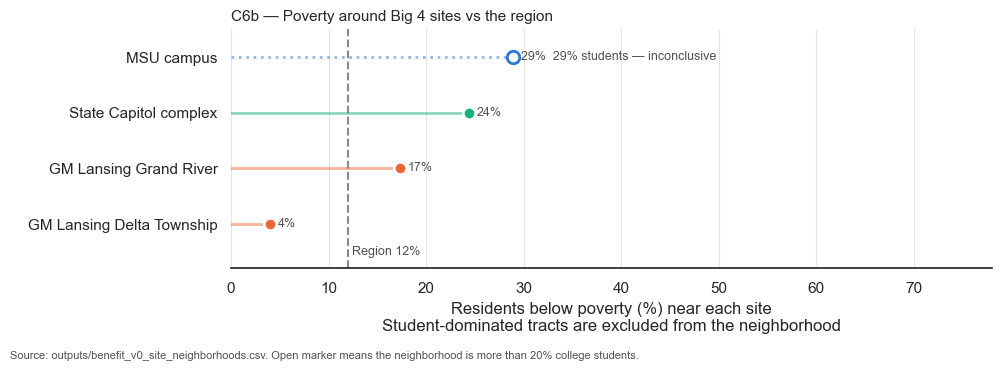

Exported      figures/20_poverty_near_sites.png


WindowsPath('C:/Users/swens/PycharmProjects/CMSE 495/NC3/figure_instructions/figures/20_poverty_near_sites.png')

In [21]:
nbhd = pd.read_csv(SCORECARD_DIR / "benefit_v0_site_neighborhoods.csv").set_index("site")
site_order = nbhd.loc[list(SITES), "poverty rate %"].sort_values().index.tolist()
region_poverty = float(nbhd.loc["Region (non-student tracts)", "poverty rate %"])
save_table(nbhd.reset_index(), "20_poverty_near_sites")

fig, ax = plt.subplots(figsize=(10, 3.6))
for i, site in enumerate(site_order):
    value = float(nbhd.loc[site, "poverty rate %"])
    color = BIG4_COLORS[SITES[site][2]]
    inconclusive = float(nbhd.loc[site, "college students %"]) > 20
    ax.plot([0, value], [i, i], color=color, lw=2, alpha=0.5, ls=":" if inconclusive else "-")
    ax.plot(
        value,
        i,
        "o",
        ms=9,
        mew=2,
        mec=color if inconclusive else "white",
        color="white" if inconclusive else color,
    )
    note = f"  {nbhd.loc[site, 'college students %']:.0f}% students — inconclusive" if inconclusive else ""
    ax.text(value + 0.8, i, f"{value:.0f}%{note}", va="center", fontsize=9, color="#52514e")
ax.axvline(region_poverty, color=REGION_COLOR, ls="--", lw=1.5)
ax.text(region_poverty + 0.4, -0.55, f"Region {region_poverty:.0f}%", fontsize=9, color="#52514e")
ax.set_yticks(range(len(site_order)), site_order)
ax.set_xlim(0, 78)
ax.set_ylim(-0.8, len(site_order) - 0.5)
ax.set_xlabel("Residents below poverty (%) near each site\nStudent-dominated tracts are excluded from the neighborhood")
for spine in ("top", "right", "left"):
    ax.spines[spine].set_visible(False)
ax.grid(axis="x", color="#e6e5e0", lw=0.8)
ax.set_axisbelow(True)
ax.set_title("C6b — Poverty around Big 4 sites vs the region", loc="left", fontsize=11)
fig.tight_layout()
source_note(fig, "Source: outputs/benefit_v0_site_neighborhoods.csv. Open marker means the neighborhood is more than 20% college students.")
export(
    fig,
    "20_poverty_near_sites",
    "Poverty rate of residents near each Big 4 site, compared with non-student tracts in the region.",
    "Individual_TeamMember_files/wangz153/03_benefit.ipynb.",
)


Intermediate  intermediate/21_jobs_vs_poverty.csv  (128 rows)


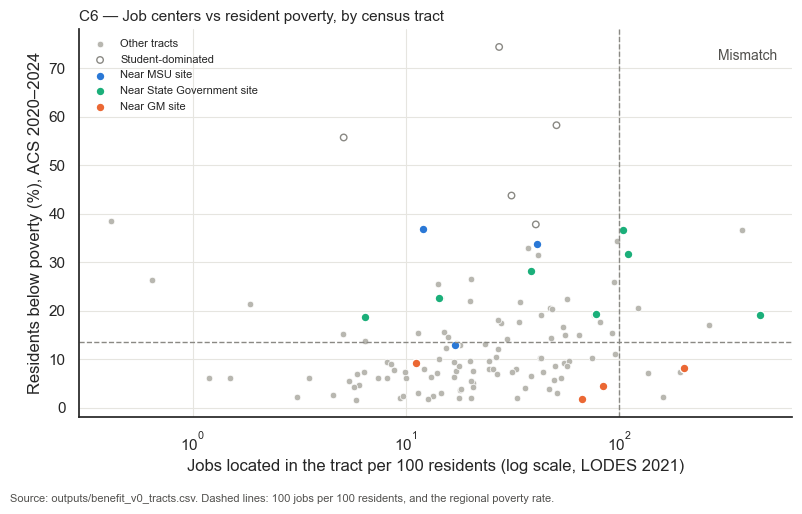

Exported      figures/21_jobs_vs_poverty.png
Regional poverty rate drawn on the chart: 13.5%


In [22]:
def km_between(lat1, lon1, lat2, lon2):
    """Approximate distance in kilometers. Same helper as nc3_helpers.km_between."""
    return np.hypot((lat2 - lat1) * 111.0, (lon2 - lon1) * 111.0 * np.cos(np.radians(lat1)))


points = pd.read_csv(SCORECARD_DIR / "benefit_v0_tracts.csv", dtype={"geoid": str})
points["small_pop"] = points["population"] < 200
points["student_tract"] = points["student_share"] > 40
region_pov_line = tracts["below_poverty"].sum() / tracts["poverty_universe"].sum() * 100


def neighborhood(lat, lon, km=2.0, min_tracts=3):
    base = points.loc[~points["small_pop"] & ~points["student_tract"]].copy()
    base["dist_km"] = km_between(lat, lon, base["lat"], base["lon"])
    selected = base[base["dist_km"] <= km]
    if len(selected) < min_tracts:
        selected = base.nsmallest(min_tracts, "dist_km")
    return selected


plotted = points.loc[~points["small_pop"] & (points["jobs_per_100_res"] > 0)].copy()
plotted["near_site"] = ""
for site, (lat, lon, _inst) in SITES.items():
    nearby = neighborhood(lat, lon)["geoid"]
    open_rows = plotted["geoid"].isin(nearby) & plotted["near_site"].eq("")
    plotted.loc[open_rows, "near_site"] = site
save_table(
    plotted[["geoid", "NAME", "jobs_per_100_res", "poverty_rate", "student_tract", "near_site"]],
    "21_jobs_vs_poverty",
)

fig, ax = plt.subplots(figsize=(8, 5))
other = plotted[(plotted["near_site"] == "") & ~plotted["student_tract"]]
students = plotted[plotted["student_tract"]]
ax.scatter(other["jobs_per_100_res"], other["poverty_rate"], s=22, color="#b8b7b0", edgecolor="white", linewidth=0.5, label="Other tracts")
ax.scatter(students["jobs_per_100_res"], students["poverty_rate"], s=22, facecolor="none", edgecolor="#8a8984", linewidth=1, label="Student-dominated")
plotted["institution"] = plotted["near_site"].map(
    lambda site: SITES[site][2] if site in SITES else ""
)
for inst in ["MSU", "State Government", "GM"]:
    selected = plotted[plotted["institution"].eq(inst) & ~plotted["student_tract"]]
    if len(selected):
        ax.scatter(
            selected["jobs_per_100_res"],
            selected["poverty_rate"],
            s=40,
            color=BIG4_COLORS[inst],
            edgecolor="white",
            linewidth=1,
            label=f"Near {inst} site",
        )
ax.set_xscale("log")
ax.axvline(100, color="#8a8984", ls="--", lw=1)
ax.axhline(region_pov_line, color="#8a8984", ls="--", lw=1)
ax.set_xlabel("Jobs located in the tract per 100 residents (log scale, LODES 2021)")
ax.set_ylabel("Residents below poverty (%), ACS 2020–2024")
ax.text(0.98, 0.95, "Mismatch", ha="right", va="top", fontsize=10, color="#52514e", transform=ax.transAxes)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
ax.grid(color="#e6e5e0", lw=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.set_title("C6 — Job centers vs resident poverty, by census tract", loc="left", fontsize=11)
fig.tight_layout()
source_note(fig, "Source: outputs/benefit_v0_tracts.csv. Dashed lines: 100 jobs per 100 residents, and the regional poverty rate.")
export(
    fig,
    "21_jobs_vs_poverty",
    "Census tracts by jobs per 100 residents and poverty rate. Highlighted tracts are near a Big 4 site.",
    "Individual_TeamMember_files/wangz153/03_benefit.ipynb.",
)
print(f"Regional poverty rate drawn on the chart: {region_pov_line:.1f}%")


## 7. Optional live Census figure

**Used in:** `notebooks/baseline_visualizations.ipynb` section 5.

This cell calls the Census ACS 5-year API for Lansing city (state `26`, place `46000`) and requests population (`B01003_001E`) and median household income (`B19013_001E`) for 2024. No API key is required for this small request. It needs an internet connection.

Leave `RUN_LIVE_CENSUS` as `False` unless you want this extra PNG. The other 21 figures do not depend on it. If the request fails, the cell prints the error and still finishes.


In [23]:
import requests

if not RUN_LIVE_CENSUS:
    print("Skipped figure 22. Set RUN_LIVE_CENSUS = True in the setup cell to call the Census API.")
else:
    url = "https://api.census.gov/data/2024/acs/acs5"
    params = {"get": "NAME,B01003_001E,B19013_001E", "for": "place:46000", "in": "state:26"}
    try:
        response = requests.get(url, params=params, timeout=30)
        response.raise_for_status()
        payload = response.json()
        lansing = pd.DataFrame(payload[1:], columns=payload[0])
        lansing["B01003_001E"] = pd.to_numeric(lansing["B01003_001E"])
        lansing["B19013_001E"] = pd.to_numeric(lansing["B19013_001E"])
        save_table(lansing, "22_lansing_census_api")
        print(lansing.to_string(index=False))

        fig, ax1 = plt.subplots()
        ax1.bar(["Population"], lansing["B01003_001E"], color="#1f77b4", width=0.4)
        ax1.set_ylabel("Total Population", color="#1f77b4")
        ax1.tick_params(axis="y", labelcolor="#1f77b4")
        ax2 = ax1.twinx()
        ax2.bar(["Median HH Income"], lansing["B19013_001E"], color="#ff7f0e", width=0.4)
        ax2.set_ylabel("Median Household Income ($)", color="#ff7f0e")
        ax2.tick_params(axis="y", labelcolor="#ff7f0e")
        ax1.set_title("Lansing City — Population and Median Household Income (ACS 2024 5-year)")
        fig.tight_layout()
        source_note(fig, "Source: Census API 2024 ACS 5-year, place 46000 in state 26. Live request, not a local CSV.")
        export(
            fig,
            "22_lansing_census_api",
            "Lansing city population and median household income from a live Census API call.",
            "notebooks/baseline_visualizations.ipynb section 5. Optional.",
        )
    except requests.RequestException as error:
        print("Optional Census API request could not be completed:", error)
        print("Figures 1–21 use local files and are still a complete run.")


Skipped figure 22. Set RUN_LIVE_CENSUS = True in the setup cell to call the Census API.


## 8. Export check

The cell below writes `intermediate/figure_index.csv` and prints every PNG from this run.
You should see figures `01` through `21`. Figure `22` appears only when `RUN_LIVE_CENSUS` is `True`.

Open `figures/` and compare a PNG with the section named in the index. Axis titles, series, and the source line under each chart are set in the cell that creates that figure.


In [24]:
index = pd.DataFrame(EXPORTED)
save_table(index, "figure_index")
print(f"Exported {len(index)} figures to {FIG_DIR.relative_to(REPO_ROOT)}")
print(index.to_string(index=False))
expected = 22 if RUN_LIVE_CENSUS else 21
if len(index) != expected:
    raise RuntimeError(f"Expected {expected} figures, wrote {len(index)}.")
print("Figure export check passed.")


Intermediate  intermediate/figure_index.csv  (21 rows)
Exported 21 figures to figure_instructions\figures
                                       file                                                                                                                                 description                                                                                                           used_in
      figures/01_laus_unemployment_rate.png                                                                Monthly not-seasonally-adjusted unemployment rate, Lansing-East Lansing MSA.                                       notebooks/baseline_visualizations.ipynb section 1; INSTALL.md demo chart 1.
          figures/02_qcew_msa_ownership.png                                                                      2024 average employment by ownership for the Lansing-East Lansing MSA.                                       notebooks/baseline_visualizations.ipynb section 2; INSTALL.md demo chart 2.
